# Histology-guided deconvolution: HER2ST G2

**Data availability.** Processed HER2ST section G2 counts, H&E images, spatial coordinates and pathological region annotations are publicly available from the [authors' Zenodo deposit](https://doi.org/10.5281/zenodo.4751624). This tutorial uses these processed data and derives the morphology features from the registered H&E image.

Combine RNA with registered H&E morphology. G2 contains **467 spots, 14,898 genes and six pathological regions**; only the **402 labelled spots** enter quantitative evaluation. Both arms start from the same count-only consensus. The H&E arm adds morphology reconstruction and morphology-gated spatial smoothing.

HIPT and UNI encode image appearance independently of RNA and pathology labels. Each encoder's spatial features are reduced by PCA to 99% cumulative variance, quantized into 16 visual words, and pooled over each capture footprint. Concatenating the two frequency vectors with equal half-mass gives $Q\in\mathbb{R}^{N\times32}$. The model jointly learns RNA profiles $B$, morphology profiles $H$ and shared weights $P$, minimizing RNA KL + weighted morphology KL + graph TV. Both morphology reconstruction and TV use exposure weighting. Morphology differences reduce smoothing across image boundaries.

## 1. Set up

Install spDecon and open this notebook from the cloned repository. The first loading cell downloads the example data automatically.

- `RUN_FIT=False`: load saved fits, display their recorded convergence summary and regenerate metrics and plots on CPU.
- `RUN_FIT=True`: train the model with the settings below. Reference-free training uses the CUDA environment.
- `VERBOSE=True`: show fitting stages, objective (loss), KKT residuals and the final convergence status. Set it to `False` to silence fitting messages.

The setup cell fixes the random seed and enables deterministic execution.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table, saved_fit_summary
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False

VERBOSE = True
print("Mode: full model fitting." if RUN_FIT else "Mode: load saved full fits; no new optimization.")


Mode: load saved full fits; no new optimization.


## 2. Load the registered image inputs and molecular data

`image_spots.csv` contains spot centers in original image pixels, with x horizontal and y vertical. Image resolution and spot radius accompany the original H&E. The supplied morphology matrix `Q` is derived from this H&E image using the extraction code below.

The AnnData object stores raw RNA in `adata.X`, graph coordinates in `obsm["spatial"]`, and the 32-column HIPT/UNI frequencies in `obsm["morphology"]`. `obsm["spatial_image"]` stores centers in the original H&E image pixels. For your own `.h5ad`, load it with `ad.read_h5ad`, extract morphology as below, and align all image-feature rows to `adata.obs_names`.

In [2]:
path,data=dataset("g2")
adata = ad.AnnData(data["Y"], obs=pd.DataFrame(index=data["spots"]),
                  var=pd.DataFrame(index=data["genes"]))
adata.obsm["spatial"] = data["coordinates"]
adata.obsm["morphology"] = data["Q"]
adata.obs["section_id"] = "G2"
image_spots = pd.read_csv(path/"image_spots.csv",index_col=0).loc[adata.obs_names]
adata.obsm["spatial_image"] = image_spots[["x", "y"]].to_numpy()
y = np.array(adata.to_df(), dtype=float, order="F")
xy, q = adata.obsm["spatial"], adata.obsm["morphology"]
print(adata)
print("Counts:",y.shape,"Morphology:",q.shape)
print("Microns/pixel:",(path/"microns_per_pixel.txt").read_text().strip())
print("Spot radius, pixels:",(path/"radius_pixels.txt").read_text().strip())


AnnData object with n_obs × n_vars = 467 × 14898
    obs: 'section_id'
    obsm: 'spatial', 'morphology', 'spatial_image'
Counts: (467, 14898) Morphology: (467, 32)
Microns/pixel: 0.6878475741620447
Spot radius, pixels: 72.69052313066803


## 3. Extract HIPT and UNI feature embeddings

Install the optional `requirements-histology.lock.txt` environment. Clone [spEnhance](https://github.com/dsong-lab/spEnhance); its encoder scripts are in the repository root. Obtain the two HIPT checkpoints `vit256_small_dino.pth` and `vit4k_xs_dino.pth` from the [official HIPT release](https://github.com/mahmoodlab/HIPT), placing them under that directory's `checkpoints/`. Request access to [MahmoodLab/UNI](https://huggingface.co/MahmoodLab/UNI) and log in locally with `hf auth login`. Model weights are obtained by each user under their original terms.

The adapter rescales the registered image to 0.5 μm/pixel, runs shifted HIPT and UNI feature extraction, then performs PCA, dictionary fitting and spot pooling. It writes intermediate embeddings, PCA transforms, visual-word dictionaries and `morphology.npz`. A new output directory is required. Extraction is optional here because the complete derived features are supplied; it uses a GPU and more memory than displaying the saved figures.

```bash
git clone https://github.com/dsong-lab/spEnhance.git external/spEnhance
```


In [3]:
from spDecon.image_features import extract_histology
EXTRACT_IMAGE = False
if EXTRACT_IMAGE:
    q_frame=extract_histology(
        path/"he.jpg",image_spots,
        microns_per_pixel=float((path/"microns_per_pixel.txt").read_text()),
        radius_pixels=float((path/"radius_pixels.txt").read_text()),
        encoder_source=ROOT/"external/spEnhance",
        output=ROOT/"outputs/g2_features",device="cuda")
    q=q_frame.loc[adata.obs_names].to_numpy()
    adata.obsm["morphology"] = q
print("Each encoder block sums to:",q.reshape(len(q),2,16).sum(axis=2).mean(axis=0))

Each encoder block sums to: [0.5 0.5]


## 4. Fit the paired RNA-only and RNA + H&E models

The G2 coefficients are frozen at image weight 0.0331071274524168 and spatial weight 0.012495695149619745. For new data, omitting these arguments invokes gradient calibration. Both arms use the same initialization, genes and spots. Pathology labels are used only in the next step.

In [4]:
from spDecon.consensus import build_consensus
from spDecon.histology import fit_histology
cal=json.loads((path/"calibration.json").read_text())
fits={}
if RUN_FIT:
    initial=build_consensus(y,6,random_state=0,verbose=VERBOSE)
    for arm in ["RNA_TV","RNA_HE_TV"]:
        result=fit_histology(y,q if arm=="RNA_HE_TV" else None,xy,6,
            image_weight=cal["image_weight"] if arm=="RNA_HE_TV" else 0.,
            spatial_weight=cal["spatial_weight"],initial_proportions=initial.consensus_proportions,
            initial_profiles=initial.consensus_profiles,random_state=0,device="cuda",max_iter=20000,verbose=VERBOSE)
        fits[arm]=result.proportions
        print(arm,result.diagnostics)
else:
    fits={arm:np.load(path/(arm+".npz"))["P"] for arm in ["RNA_TV","RNA_HE_TV"]}
    for arm in fits:
        saved_fit_summary("g2", arm)


[saved fit] g2/RNA_TV loaded | recorded status=converged | iterations=2600 | objective=1.06707575
[saved fit] This cell loaded a previous full fit; no new optimization was run.


[saved fit] g2/RNA_HE_TV loaded | recorded status=converged | iterations=1480 | objective=1.09091905
[saved fit] This cell loaded a previous full fit; no new optimization was run.


/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: Futur

## 5. Compare pathological structure on the fixed support

PCC compares aligned component weights with one-hot region labels. ARI compares dominant-component assignments with pathology. Boundary F1 compares edges crossing predicted versus true region boundaries, restricting both ends to the 402-spot support. These are complete-section results from the supplied reproduction, not values copied from a manuscript figure.

Each vertical stem ends at the measured score: blue denotes RNA, and rose denotes RNA + H&E. All three axes span 0–1. There is one section and no biological-replicate uncertainty estimate.

,model,PCC,ARI,Boundary F1,n
0,RNA_TV,0.447552,0.2472,0.428571,402
1,RNA_HE_TV,0.541291,0.3816,0.474438,402


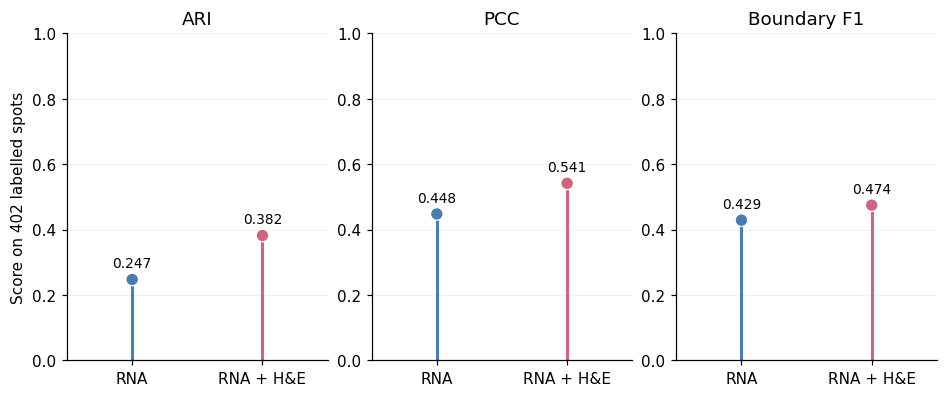

In [5]:
from sklearn.metrics import adjusted_rand_score, f1_score
support = pd.Index(data["spots"]).get_indexer(data["support"])
labels = np.sort(np.unique(data["annotations"][support]))
codes = pd.Categorical(data["annotations"][support], categories=labels).codes
truth = np.eye(len(labels))[codes]
position = np.full(len(y), -1)
position[support] = np.arange(len(support))
ii, jj = position[data["edge_i"]], position[data["edge_j"]]
keep = (ii >= 0) & (jj >= 0)
ii, jj = ii[keep], jj[keep]
rows, region_rows, mapped = [], [], {}
for arm, p in fits.items():
    matched, order = align(p[support], truth)
    mapped[arm] = p[:, order]
    region_pcc = np.diag(correlation(matched, truth))
    pred = matched.argmax(axis=1)
    rows.append({"model": arm, "PCC": region_pcc.mean(),
                 "ARI": adjusted_rand_score(codes, pred),
                 "Boundary F1": f1_score(codes[ii] != codes[jj], pred[ii] != pred[jj]),
                 "n": len(support)})
    region_rows.extend({"model": arm, "region": name, "PCC": value}
                       for name, value in zip(labels, region_pcc))
scores = pd.DataFrame(rows)
region_scores = save_table(pd.DataFrame(region_rows), "g2_region_pcc")
display(save_table(scores, "g2_paired_metrics"))

method_colors = ["#477DB3", "#CE647D"]
fig, axes = plt.subplots(1, 3, figsize=(8.5, 3.5), layout="constrained")
for ax, metric in zip(axes, ["ARI", "PCC", "Boundary F1"]):
    values = scores[metric].to_numpy()
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color="#eeeeee", linewidth=.6)
    ax.vlines([0, 1], 0, values, colors=method_colors, linewidth=2)
    ax.scatter([0, 1], values, c=method_colors, s=68,
               edgecolors="white", linewidths=.8, zorder=3)
    for j, value in enumerate(values):
        ax.annotate(f"{value:.3f}", (j, value), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=9)
    ax.set(xticks=[0, 1], xticklabels=["RNA", "RNA + H&E"],
           ylim=(0, 1), xlim=(-.5, 1.5), title=metric)
axes[0].set_ylabel("Score on 402 labelled spots")
save_figure(fig, "g2_improvement")


## 6. Inspect each pathological region

The paired markers show the PCC between a matched component and each region's one-hot label, using all 402 labelled spots. Blue circles denote RNA; rose squares denote RNA + H&E. Grey lines connect the two values for the same region. The full values are exported to `outputs/tables/g2_region_pcc.csv`. Improvement varies by region: the breast-gland correlations are negative in both arms, and the invasive-cancer correlation decreases slightly. The axis includes these values.

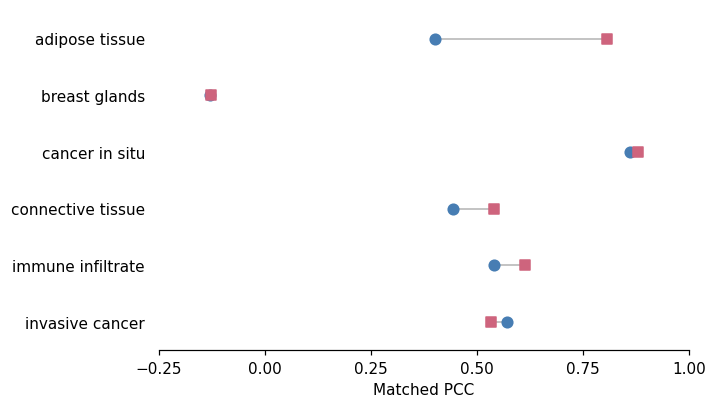

In [6]:
paired = region_scores.pivot(index="region", columns="model", values="PCC").loc[labels]
fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
positions = np.arange(len(labels))
for i, (_, row) in enumerate(paired.iterrows()):
    ax.plot([row["RNA_TV"], row["RNA_HE_TV"]], [i, i],
            color="#b9b9b9", linewidth=1.1, zorder=1)
ax.scatter(paired["RNA_TV"], positions, c=method_colors[0], marker="o", s=48, zorder=2)
ax.scatter(paired["RNA_HE_TV"], positions, c=method_colors[1], marker="s", s=44, zorder=2)
ax.set(yticks=positions, yticklabels=labels, xlabel="Matched PCC",
       xlim=(-.25, 1), xticks=[-.25, 0, .25, .5, .75, 1], ylim=(len(labels)-.5, -.5))
ax.tick_params(axis="y", length=0, pad=9)
ax.spines["left"].set_visible(False)
save_figure(fig, "g2_region_pcc")


## 7. Display H&E and spatial mixtures

The image below has four columns, from left to right: **original H&E, pathology, RNA, RNA + H&E**. The upper row shows the whole labelled region; the lower row enlarges the outlined window. The figure itself contains no text. The original image colors are retained in the first column; the same image is faded behind the spot overlays in the other columns. Pathology uses solid circles, and model results use mixture pies rather than only the largest component. All four columns use original image pixel coordinates.

The window is the fixed crop from the manuscript's G2 spatial figure. It was originally chosen to illustrate improved boundaries and is not an independent evaluation region. The metrics above use all 402 labelled spots. All 467 spots remain in model fitting; only the common labelled support is shown here.

The six region colors are: adipose tissue, blue-grey (`#73A4B6`); breast glands, ochre (`#DD9A3E`); cancer in situ, lavender (`#A68BAF`); connective tissue, sage (`#8AA881`); immune infiltrate, rose (`#C46E89`); invasive cancer, blue (`#4C689B`). Components are matched to the same region order separately for each arm.

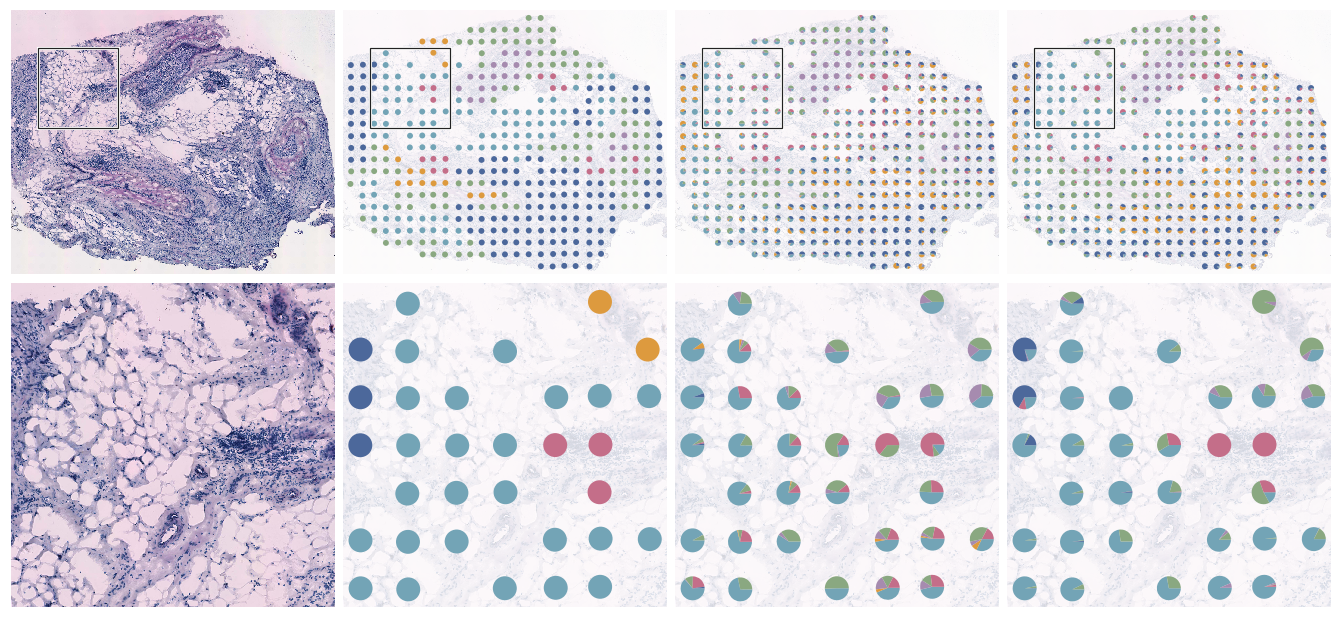

In [7]:
from PIL import Image
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle, Rectangle, Wedge

# This supplied full-resolution image is 9,326 × 9,863 pixels.
Image.MAX_IMAGE_PIXELS = None
image_xy = image_spots.loc[data["spots"][support], ["x", "y"]].to_numpy()
radius = float((path / "radius_pixels.txt").read_text())
region_colors = ["#73A4B6", "#DD9A3E", "#A68BAF", "#8AA881", "#C46E89", "#4C689B"]
zoom = [1030.5094074245112, 2997.1505925754886,
        1905.379407424511, 3872.0205925754885]  # x0, x1, y0, y1
with Image.open(path / "he.jpg") as image:
    margin = 2.5 * radius
    whole = [max(0, min(image_xy[:, 0].min()-margin, zoom[0])),
             min(image.width, max(image_xy[:, 0].max()+margin, zoom[1])),
             max(0, min(image_xy[:, 1].min()-margin, zoom[2])),
             min(image.height, max(image_xy[:, 1].max()+margin, zoom[3]))]
    backgrounds = []
    for x0, x1, y0, y1 in [whole, zoom]:
        size = (1400, round(1400 * (y1-y0) / (x1-x0)))
        backgrounds.append(np.asarray(image.resize(
            size, Image.Resampling.LANCZOS, box=(x0, y0, x1, y1),
            reducing_gap=2).convert("RGB")))

aspect = (whole[3]-whole[2]) / (whole[1]-whole[0])
fig, axes = plt.subplots(2, 4, figsize=(12, 3*(aspect+1)),
                         gridspec_kw={"height_ratios": [aspect, 1]})
for row, bounds in enumerate([whole, zoom]):
    x0, x1, y0, y1 = bounds
    visible = ((image_xy[:, 0] >= x0) & (image_xy[:, 0] <= x1) &
               (image_xy[:, 1] >= y0) & (image_xy[:, 1] <= y1))
    for col, ax in enumerate(axes[row]):
        ax.imshow(backgrounds[row], extent=[x0, x1, y1, y0],
                  alpha=1 if col == 0 else .18, interpolation="none")
        if col:
            patches, colors = [], []
            if col == 1:
                patches = [Circle(center, radius) for center in image_xy[visible]]
                colors = np.asarray(region_colors)[codes[visible]]
            else:
                weights = mapped[["RNA_TV", "RNA_HE_TV"][col-2]][support]
                for center, values in zip(image_xy[visible], weights[visible]):
                    angles = np.r_[0, np.cumsum(values)] * 360
                    for k, value in enumerate(values):
                        if value > 0:
                            patches.append(Wedge(center, radius, angles[k], angles[k+1]))
                            colors.append(region_colors[k])
            ax.add_collection(PatchCollection(patches, facecolors=colors,
                                              edgecolors="none", linewidths=0))
        if row == 0:
            for color, width in [("white", 2), ("#222222", .8)]:
                ax.add_patch(Rectangle((zoom[0], zoom[2]), zoom[1]-zoom[0],
                                       zoom[3]-zoom[2], fill=False,
                                       edgecolor=color, linewidth=width))
        ax.set(xlim=(x0, x1), ylim=(y1, y0), aspect="equal")
        ax.axis("off")
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=.025, hspace=.025)
save_figure(fig, "g2_regions")
